In [1]:
import sys

import matplotlib.pyplot as plt

sys.path = [p for p in sys.path if "positron-python" not in p]

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc

import myutils

In [2]:
workspace,experiment=myutils.workspace()
data_dir = workspace/"experiment02-PBMC/results/scanpy_workflow"

# PBMC3k

In [3]:
data_file = data_dir / 'pbmc3k_scanpy_annotated_retro.h5ad'
assert data_file.exists()
adata = ad.read_h5ad(data_file)
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'n_genes', 'outlier', 'leiden', 'celltype'
    var: 'gene_ids', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'
    layers: 'counts', 'scaled', None (.X)

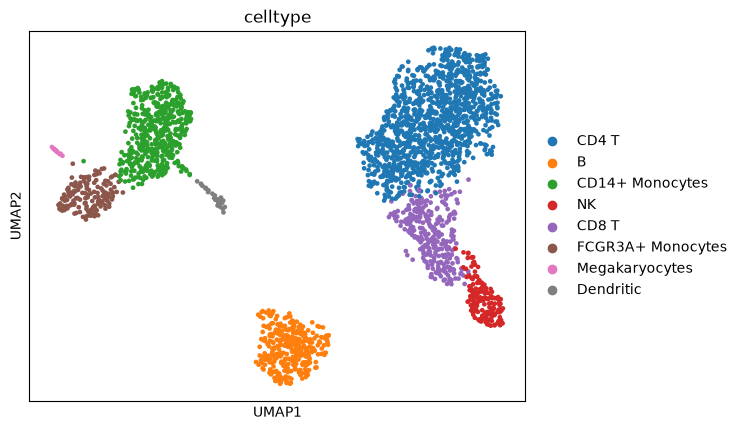

In [4]:
sc.pl.umap(adata, color="celltype")

In [5]:
np.random.seed(42)
n_cells = int(adata.n_obs * 0.3)
selected_idx = np.random.choice(adata.n_obs, n_cells, replace=False)
adata.obs['str_batch'] = '1'
batch_1_cells = adata.obs_names[selected_idx]
adata.obs.loc[batch_1_cells, 'str_batch'] = '0'


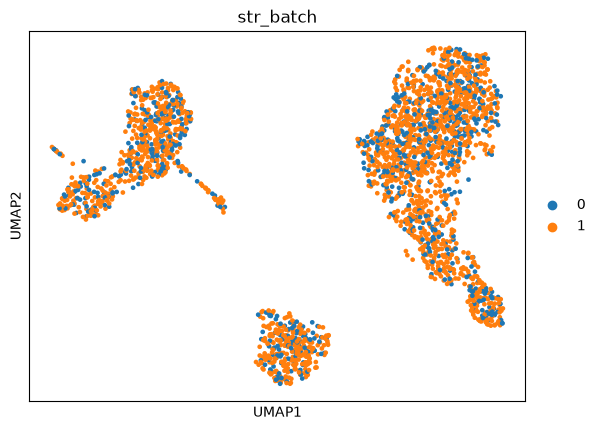

In [ ]:
sc.pl.umap(adata, color="str_batch")

In [7]:
print(sum(adata.obs.str_batch == '0') / adata.n_obs, sum(adata.obs.str_batch == '1') / adata.n_obs)
print(sum(adata.obs.str_batch == '0'),sum(adata.obs.str_batch == '1'))

0.2998483699772555 0.7001516300227445
791 1847


In [8]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'n_genes', 'outlier', 'leiden', 'celltype', 'str_batch'
    var: 'gene_ids', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'celltype_colors', 'str_batch_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'
    layers: 'counts', 'scaled', None (.X)

In [9]:
adata.write_h5ad(experiment/'data/pbmc3k_scanpy_annotated_batches.h5ad')

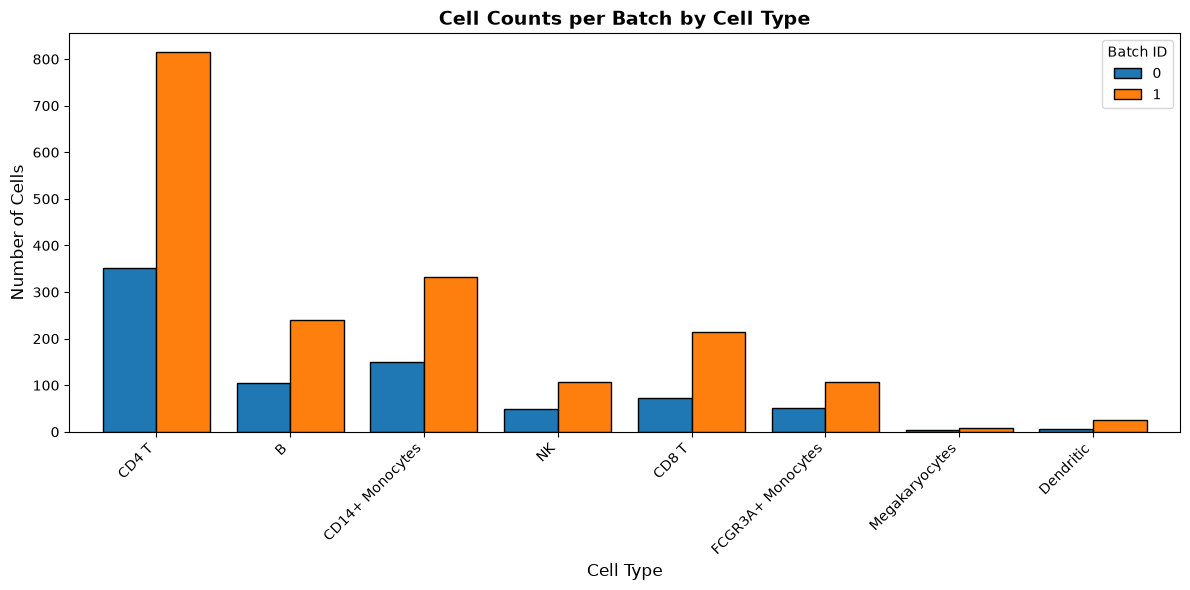

In [10]:
cell_counts = pd.crosstab(adata.obs['celltype'], adata.obs['str_batch'])
cell_counts.plot(kind='bar', stacked=False, figsize=(12, 6), edgecolor='black', width=0.8)

# 3. Add layout styling
plt.title("Cell Counts per Batch by Cell Type", fontsize=14, fontweight='bold')
plt.xlabel("Cell Type", fontsize=12)
plt.ylabel("Number of Cells", fontsize=12)
plt.xticks(rotation=45, ha='right')  # Tilts the labels so they don't overlap
plt.legend(title="Batch ID")
plt.tight_layout()

plt.show()

In [11]:
cell_counts.to_csv(experiment/'data/pbmc3k_cellcount.csv')
cell_counts.sort_values('0')

str_batch,0,1
celltype,,
Megakaryocytes,5,8
Dendritic,6,25
NK,50,107
FCGR3A+ Monocytes,51,106
CD8 T,73,214
B,104,240
CD14+ Monocytes,150,332
CD4 T,352,815


# Heroes

In [12]:
adata_subset = ad.read_h5ad(workspace / 'data/scvi_pools/heroes_pool7_scRNA.h5ad')
print(adata_subset.X.min())
adata_subset

-2.0192707145887763


AnnData object with n_obs × n_vars = 10987 × 5676
    obs: 'X.1', 'X', 'assignment', 'celltype', 'seurat_clusters', 'pool', 'Cohort', 'Entity', 'Fusion', 'Episode', 'PID', 'Location', 'barcode_sample', 'consensus_celltype'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'Entity_colors', 'consensus_celltype_colors', 'hvg', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap', 'X_umap_scanpy'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'
    layers: None (.X)

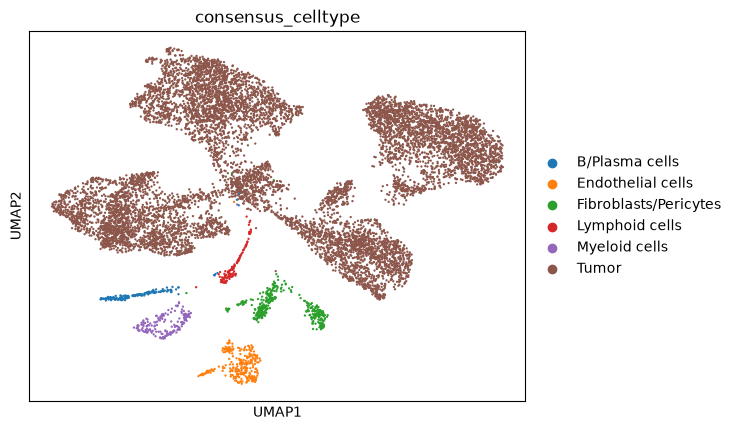

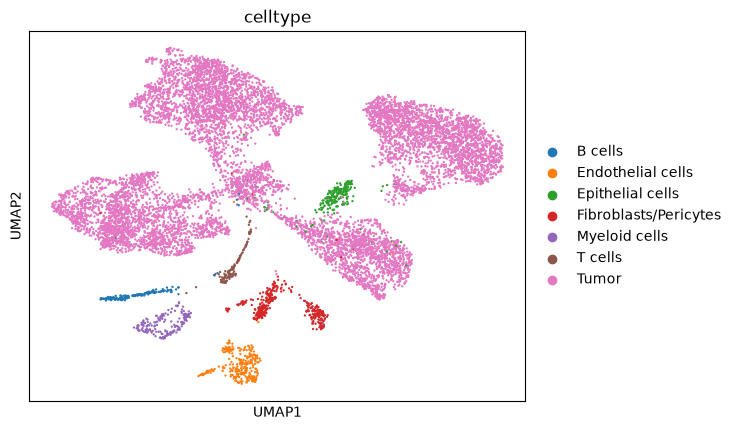

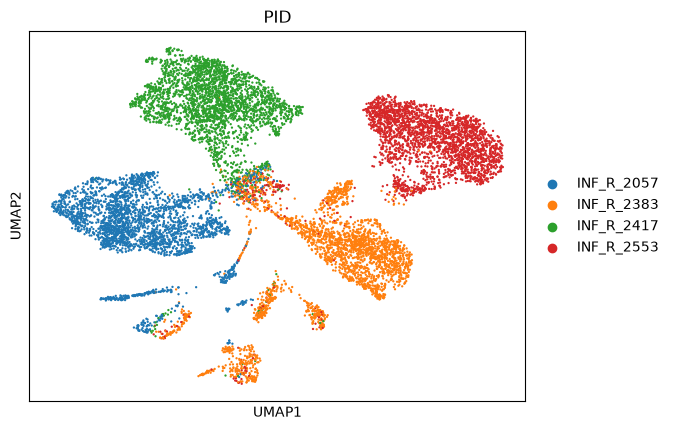

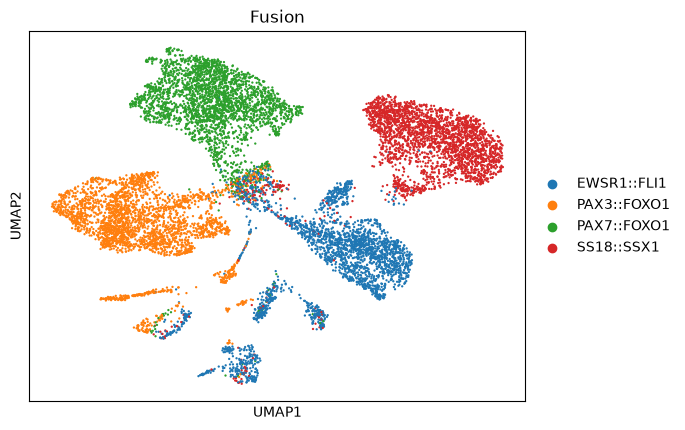

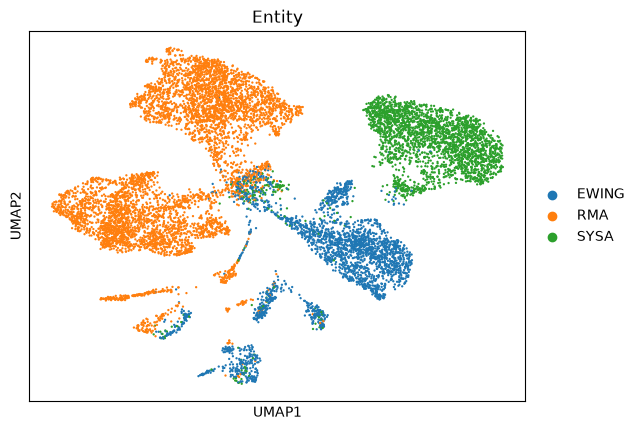

In [13]:
sc.pl.umap(adata_subset, color="consensus_celltype")
sc.pl.umap(adata_subset, color="celltype")
sc.pl.umap(adata_subset, color="PID")
sc.pl.umap(adata_subset, color="Fusion")
sc.pl.umap(adata_subset, color="Entity")

In [14]:
data_file = workspace / 'data/scvi_pools/heroes_pool7_scRNA_positive.h5ad'
assert data_file.exists()
adata = ad.read_h5ad(data_file)
adata

AnnData object with n_obs × n_vars = 10987 × 35929
    obs: 'pool', 'assignment', 'celltype', 'seurat_clusters', 'Cohort', 'Entity', 'Fusion', 'Episode', 'PID', 'Location', 'barcode_sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', '_scvi_batch', '_scvi_labels', 'leiden', 'X', 'final'
    var: 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'celltype_colors', 'final_colors', 'leiden', 'log1p', 'neighbors', 'umap'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    obsp: 'connectivities', 'distances'
    layers: 'counts', 'scvi_normalized', None (.X)

In [15]:
print(adata.var.head().index)
adata.X.min()

Index(['MIR1302-2HG', 'OR4F5', 'AL627309.1', 'AL627309.3', 'AL627309.2'], dtype='str')


np.float32(0.0)

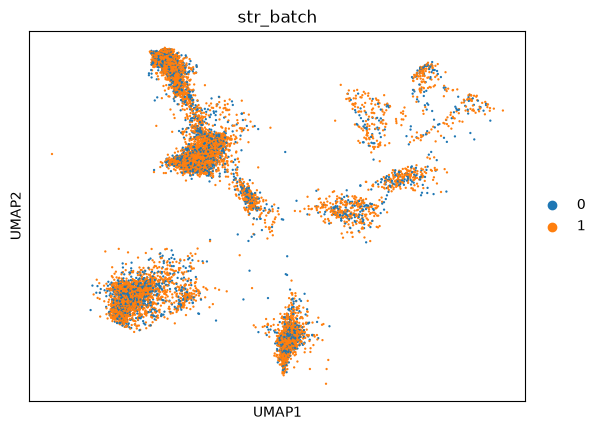

In [16]:
np.random.seed(42)
n_cells = int(adata.n_obs * 0.3)
selected_idx = np.random.choice(adata.n_obs, n_cells, replace=False)
adata.obs['str_batch'] = '1'
batch_1_cells = adata.obs_names[selected_idx]
adata.obs.loc[batch_1_cells, 'str_batch'] = '0'
adata.obs.loc[adata_subset.obs_names, 'consensus_celltype'] = adata_subset.obs.consensus_celltype
sc.pl.umap(adata, color="str_batch")

True


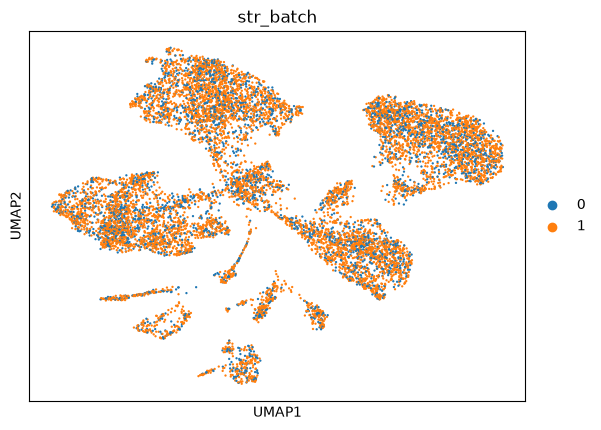

In [17]:
print(all(adata_subset.obs.index == adata.obs.index))
adata_subset.obs['str_batch'] = adata.obs['str_batch']
sc.pl.umap(adata_subset, color="str_batch")
adata_subset.write_h5ad(workspace / 'data/scvi_pools/heroes_pool7_scRNA_batches.h5ad')


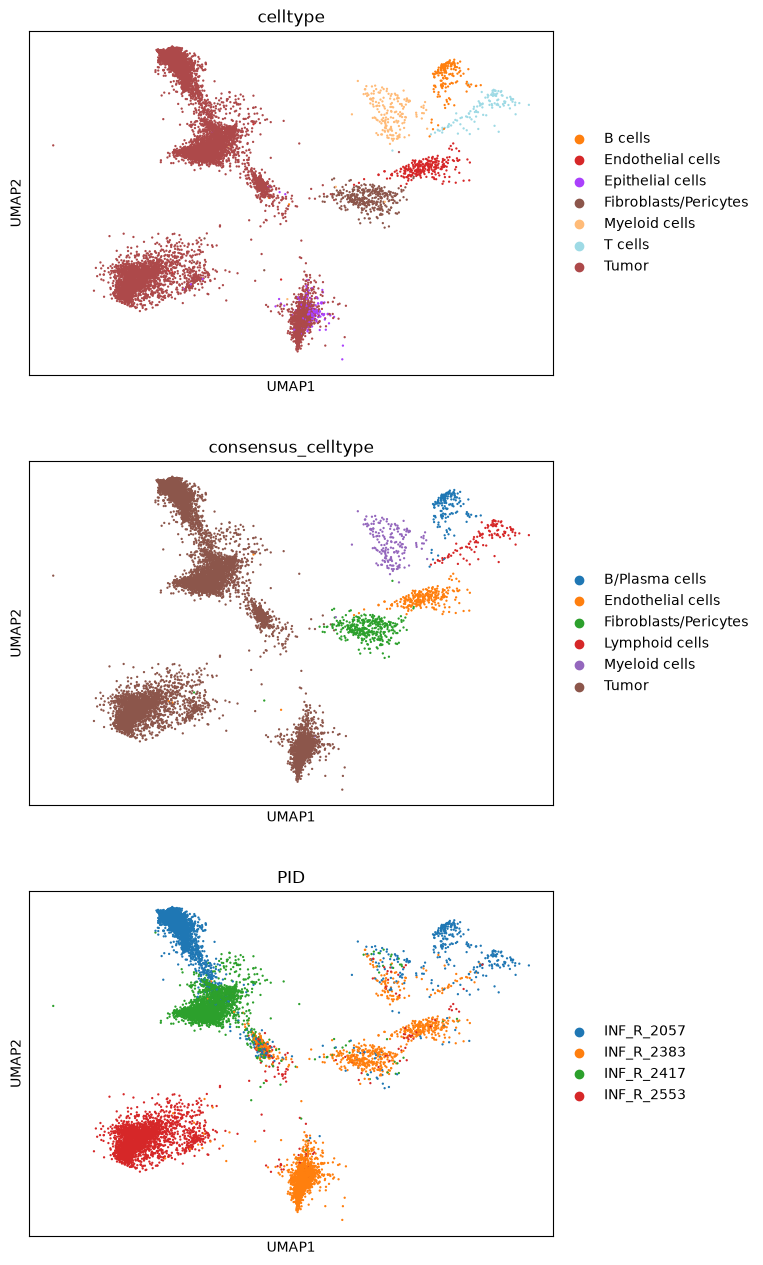

In [18]:
sc.pl.umap(adata, color=["celltype","consensus_celltype","PID"], ncols=1)

In [19]:
print(sum(adata.obs.str_batch == '0') / adata.n_obs, sum(adata.obs.str_batch == '1') / adata.n_obs)
print(sum(adata.obs.str_batch == '0'),sum(adata.obs.str_batch == '1'))

0.2999908983343952 0.7000091016656048
3296 7691


In [20]:
adata.uns

{'_scvi_manager_uuid': '0e10000e-3a0d-4015-921f-ad322a16ef19',
 '_scvi_uuid': '505d7a4d-635b-4b2e-a6fe-3cf8b8dec8d8',
 'celltype_colors': array(['#ff7f0e', '#d62728', '#aa40fc', '#8c564b', '#ffbb78', '#9edae5',
        '#ad494a'], dtype=object),
 'final_colors': array(['#1f77b4', '#ff7f0e', '#d62728', '#8c564b', '#b5bd61', '#17becf'],
       dtype=object),
 'leiden': {'params': {'n_iterations': -1,
   'random_state': 0,
   'resolution': 0.5}},
 'log1p': {'base': None},
 'neighbors': {'connectivities_key': 'connectivities',
  'distances_key': 'distances',
  'params': {'method': 'umap',
   'metric': 'euclidean',
   'n_neighbors': 15,
   'random_state': 0,
   'use_rep': 'X_scVI'}},
 'umap': {'params': {'a': 0.5830300203968329, 'b': 1.3341669926352966}},
 'str_batch_colors': ['#1f77b4', '#ff7f0e'],
 'consensus_celltype_colors': ['#1f77b4',
  '#ff7f0e',
  '#2ca02c',
  '#d62728',
  '#9467bd',
  '#8c564b'],
 'PID_colors': ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']}

In [21]:
adata.uns = {}
adata.layers.clear()
adata.write_h5ad(experiment/'data/hereos_pool7_scRNA_batches.h5ad')
adata

AnnData object with n_obs × n_vars = 10987 × 35929
    obs: 'pool', 'assignment', 'celltype', 'seurat_clusters', 'Cohort', 'Entity', 'Fusion', 'Episode', 'PID', 'Location', 'barcode_sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', '_scvi_batch', '_scvi_labels', 'leiden', 'X', 'final', 'str_batch', 'consensus_celltype'
    var: 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    obsp: 'connectivities', 'distances'
    layers: None (.X)

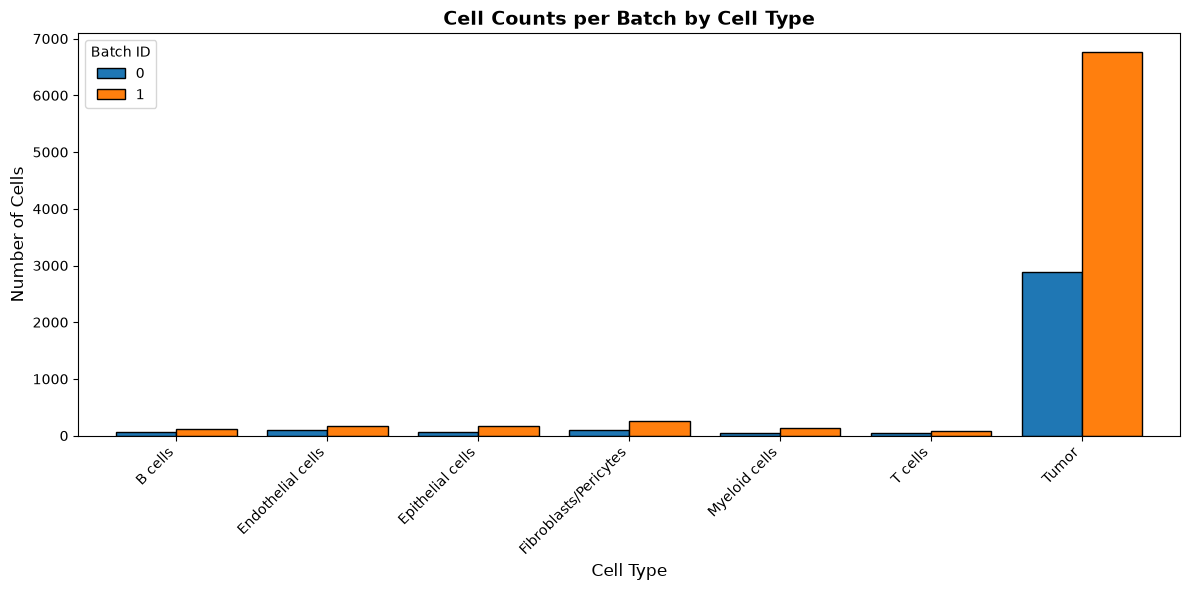

In [22]:
cell_counts = pd.crosstab(adata.obs['celltype'], adata.obs['str_batch'])
cell_counts.plot(kind='bar', stacked=False, figsize=(12, 6), edgecolor='black', width=0.8)

# 3. Add layout styling
plt.title("Cell Counts per Batch by Cell Type", fontsize=14, fontweight='bold')
plt.xlabel("Cell Type", fontsize=12)
plt.ylabel("Number of Cells", fontsize=12)
plt.xticks(rotation=45, ha='right')  # Tilts the labels so they don't overlap
plt.legend(title="Batch ID")
plt.tight_layout()

plt.show()

In [23]:
cell_counts.to_csv(experiment/'data/heroes_cellcount.csv')
cell_counts.sort_values('0')

str_batch,0,1
celltype,,
T cells,40,75
Myeloid cells,48,139
B cells,56,112
Epithelial cells,65,165
Endothelial cells,91,178
Fibroblasts/Pericytes,102,262
Tumor,2894,6760


In [24]:
adata.uns.clear()
adata.layers.clear()
adata.obsm.clear()
adata.obsp.clear()
adata.write_h5ad(experiment/'data/hereos_pool7_scRNA_batches_small.h5ad')
adata

AnnData object with n_obs × n_vars = 10987 × 35929
    obs: 'pool', 'assignment', 'celltype', 'seurat_clusters', 'Cohort', 'Entity', 'Fusion', 'Episode', 'PID', 'Location', 'barcode_sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', '_scvi_batch', '_scvi_labels', 'leiden', 'X', 'final', 'str_batch', 'consensus_celltype'
    var: 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    layers: None (.X)